# Ball on the inner raceway of a deep groove ball bearing: SlipPY static BEM against Hertz

**Case:** `validation/contact/hertz_ellipse` (V-DRY-02), criteria E3-E5 of the README for the
bearing contact.

Elliptical point contact, long across rolling (the groove conforms to the ball, $R_y/R_x \approx 32$,
outside the rows of Hamrock & Brewe's tables). The sweep runs on the hand-written case
(`construction.CASE`, SI, load 4.448 N); the AxisForge bearing of `construction.py` is then passed
through the bridge, checked to be the same contact (by value: its `case_hash` may differ in the
last bit after the mm -> m conversion) and solved once on the default grid.

The judge is `references.contact.hertz.hertz_point` (Johnson 1985, ch. 4), self-checked against
Hamrock & Brewe's Tables 1-2 in `02_ratio`. The bridge record's `err_*` (against SlipPY's
`hertz_full`) stay in the CSV as information. `--smoke`: the coarsest grid ($2h_0$), composite
build only.

In [1]:
import math
import sys

import numpy as np
import matplotlib.pyplot as plt
from axisforge.outputs._format import format_table, write_records_csv

from references.contact.hertz import hertz_point
from slippy_bridge.contact import Grid, contacts, pair, static_step
from validation._support.convergence import RECORD_COLUMNS, sweep
from validation._support.figures import contact_plots
from validation._support.style import use_style

from construction import CASE, H_LEVELS, RESULTS, SPAN_X_0, SPAN_X_LEVELS, ball_bearing

use_style()                                       # house paper style (style/README.md)
SMOKE = "--smoke" in sys.argv                     # step-7 smoke run; a notebook runs the full grids
NAME = "01_ball_raceway"
RESULTS.mkdir(exist_ok=True)                      # git-ignored (D-0020)
BUILDS = ("composite",) if SMOKE else ("composite", "two_profiles")
H_RUN = (2.0,) if SMOKE else H_LEVELS             # grid spacings in units of h0 [-]
SPAN_RUN = () if SMOKE else SPAN_X_LEVELS         # domain half-lengths in units of s_x [-]

JUDGE = hertz_point(CASE.r1, CASE.r2, CASE.E, CASE.nu, CASE.load)

## 1. Mesh and domain sweep, then the AxisForge bearing

In [2]:
records = sweep(CASE, BUILDS, H_RUN, SPAN_RUN, RESULTS / "slippy_01", span_x_0=SPAN_X_0)

# AxisForge link: the bearing (mm, N, MPa) through the bridge must give the case contact (SI).
# The mm -> m conversion may change the last bit, so values are compared, not the case hash.
link = contacts(ball_bearing(), load=CASE.load, races=("inner",))[0]
c = link.case
np.testing.assert_allclose(c.r1 + c.r2 + c.E + c.nu + (c.load,),
                           CASE.r1 + CASE.r2 + CASE.E + CASE.nu + (CASE.load,), rtol=1e-12, atol=0.0)
h0 = Grid.around(c).h
grid = Grid.around(c, h=2.0 * h0 if SMOKE else None, span_x=SPAN_X_0)   # the default grid (smoke: 2 h0)
record, p = static_step.run(link, pair(c, grid), grid, RESULTS / "slippy_01", name=f"{CASE.label}_axisforge")
# written beside the sweep, but kept out of the convergence figure
table = records + [{"build": "composite", "sweep": "axisforge", "span_x": SPAN_X_0,
                    "use_frequency_domain": True, **record}]
KEYS = {"s_x": "s_x_m", "s_y": "s_y_m", "p0": "p0_Pa", "delta": "delta_m"}   # quantity -> record/judge key
for r in table:                                   # errors against the judge (fractions)
    r.update({f"eps_{q}": r[k] / JUDGE[k] - 1.0 for q, k in KEYS.items()})

print(f"{CASE.label}   case_hash {CASE.case_hash()}   judge: s_x {JUDGE['s_x_m'] * 1e6:.3f} um, "
      f"s_y {JUDGE['s_y_m'] * 1e6:.3f} um, p0 {JUDGE['p0_Pa'] * 1e-6:.2f} MPa, delta {JUDGE['delta_m'] * 1e9:.2f} nm")
print(format_table(RECORD_COLUMNS, table))
print(f"\nAxisForge link: PASS  {link.subtype} {link.location['race']} race gives the case contact "
      f"within 1e-12 (case_hash {c.case_hash()})")

ball_raceway   case_hash da11fec58411164e   judge: s_x 27.396 um, s_y 251.731 um, p0 307.96 MPa, delta 264.10 nm
       build      sweep  span_x [s_x]  h [um]  n_x   n_y  p0 [MPa]  err p0 [%]  err s_x [%]  err s_y [%]  err delta [%]  t [s]
------------  ---------  ------------  ------  ---  ----  --------  ----------  -----------  -----------  -------------  -----
   composite       mesh             4   3.815   60   174    307.01      -0.309       -1.140       +0.827         +0.391   0.94
   composite       mesh             4   1.907  118   346    306.82      -0.369       -1.224       +0.820         +0.444   2.01
   composite       mesh             4   0.954  232   690    306.78      -0.383       -0.890       +0.835         +0.523   4.97
   composite       mesh             4   0.477  462  1376    306.76      -0.387       -0.683       +0.851         +0.528  17.41
   composite     domain             2   1.907   60   346    299.82      -2.641       -2.528       +5.414         +8.004   1.3

## 2. Criteria

On the default grid ($h_0$, half-length $4 s_x$; smoke: $2h_0$) per build, and on the AxisForge
contact: E3 $s_x$, $s_y$, $p_0$ within 1 %; E4 $\delta$ within 2 % **[proposed]**; E5 the major axis
lies across rolling, on array axis 1 ($s_y > s_x$, judge and BEM).

In [3]:
def row(cid, quantity, build, value, expected, err, limit, ok):
    """One criteria record."""
    return {"id": cid, "quantity": quantity, "build": build, "value": value, "expected": expected,
            "err": err, "limit": limit, "result": "PASS" if ok else "FAIL"}


h0_case = Grid.around(CASE).h
criteria = []
for build in BUILDS + ("axisforge",):
    if build == "axisforge":
        d = table[-1]
    else:
        mesh = [r for r in records if r["build"] == build and r["sweep"] == "mesh"]
        default = [r for r in mesh if r["h_m"] == h0_case]
        if not default and not SMOKE:
            raise RuntimeError(f"no record on the default grid h0 = {h0_case} m for build {build}")
        d = default[0] if default else mesh[0]                      # smoke: the only grid, 2 h0
    for q in ("s_x", "s_y", "p0"):
        criteria.append(row("E3", q, build, d[KEYS[q]], JUDGE[KEYS[q]], d[f"eps_{q}"], "<= 0.01",
                            abs(d[f"eps_{q}"]) <= 0.01))
    criteria.append(row("E4", "delta [proposed]", build, d["delta_m"], JUDGE["delta_m"], d["eps_delta"], "<= 0.02",
                        abs(d["eps_delta"]) <= 0.02))
    criteria.append(row("E5", "s_y / s_x (major axis on array axis 1)", build, d["s_y_m"] / d["s_x_m"],
                        JUDGE["s_y_m"] / JUDGE["s_x_m"], math.nan, "> 1 (BEM and judge)",
                        d["s_y_m"] > d["s_x_m"] and JUDGE["s_y_m"] > JUDGE["s_x_m"]))

print(format_table((("id", "ID", "s"), ("quantity", "quantity", "s"), ("build", "build", "s"),
                    ("value", "value", ".6g"), ("expected", "expected", ".6g"), ("err", "err [%]", "+.4f", 100.0),
                    ("limit", "limit", "s"), ("result", "result", "s")), criteria))
write_records_csv(RESULTS / f"{NAME}.csv", table)
write_records_csv(RESULTS / f"{NAME}_criteria.csv", criteria)

ID                                quantity         build        value     expected  err [%]                limit  result
--  --------------------------------------  ------------  -----------  -----------  -------  -------------------  ------
E3                                     s_x     composite  2.70601e-05  2.73955e-05  -1.2245              <= 0.01    FAIL
E3                                     s_y     composite  0.000253795  0.000251731  +0.8200              <= 0.01    PASS
E3                                      p0     composite   3.0682e+08  3.07957e+08  -0.3690              <= 0.01    PASS
E4                        delta [proposed]     composite  2.65275e-07  2.64103e-07  +0.4438              <= 0.02    PASS
E5  s_y / s_x (major axis on array axis 1)     composite      9.37895      9.18877        -  > 1 (BEM and judge)    PASS
E3                                     s_x  two_profiles   2.7063e-05  2.73955e-05  -1.2137              <= 0.01    FAIL
E3                              

## 3. Figures

Convergence of the bridge errors (information) and the pressure through the centre of the
AxisForge contact against the Hertz pressure.

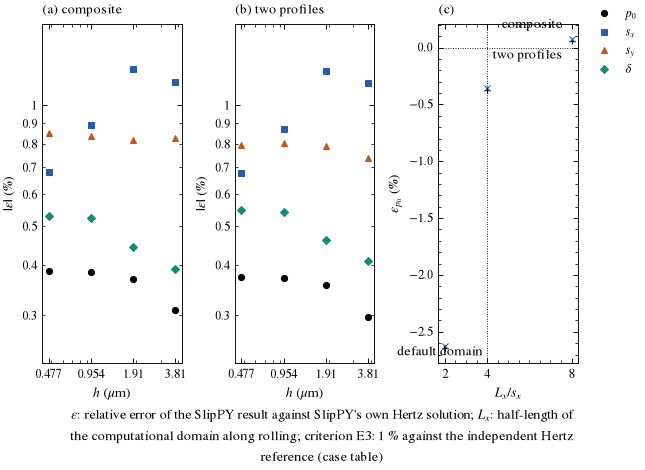

In [4]:
fig = contact_plots.convergence(records, RESULTS / f"{NAME}_convergence.png",
                                criterion=("E3", 1.0),   # p0, s_x, s_y (section 2), in the note only
                                default_span=SPAN_X_0)
plt.close(fig)                                    # shown once, by the line below
fig

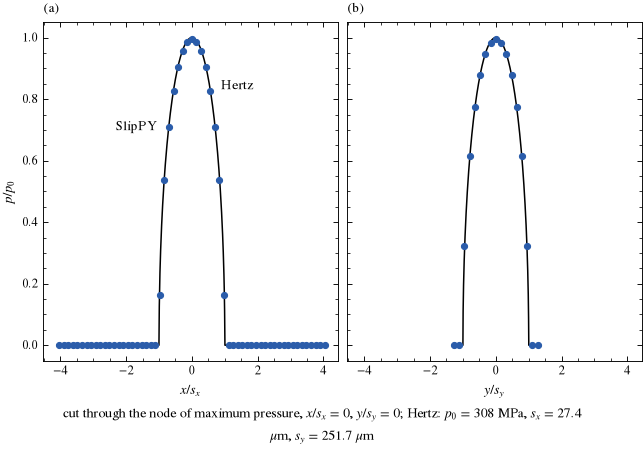

In [5]:
fig = contact_plots.pressure_cuts(p, grid, JUDGE, RESULTS / f"{NAME}_pressure_cuts.png")
plt.close(fig)                                    # shown once, by the line below
fig